# TP1 — Le réseau du métro de Montréal
## Carnet, graphes, Dijkstra — et un premier modèle

**Nom :** _Laura SORRO_ &nbsp;&nbsp;&nbsp; **Coéquipier :** _pas de coéquipier_ &nbsp;&nbsp;&nbsp; **Groupe :** _LauraS_

---

Ce TP se fait **seul ou en équipe de 2**. Une équipe remet **un seul carnet** et
indique à la fin qui a fait quoi.

**Chaque question, y compris les questions de code, se termine par une cellule
d'observation en Markdown.** Écrivez-y ce que vous constatez, en phrases complètes,
en français. Une cellule d'observation laissée telle quelle vaut 0 pour la question.

Avant de remettre : **Kernel → Redémarrer et tout exécuter**.

## Partie 2 — Charger et explorer le réseau

Le fichier `donnees/metro_montreal.csv` contient une ligne par lien entre deux
stations voisines, avec la durée approximative en minutes. Le fichier
`donnees/stations.csv` donne la ligne de chaque station.

In [1]:
import csv

reseau = {}

with open("donnees/metro_montreal.csv", encoding="utf-8") as fichier:
    for ligne in csv.DictReader(fichier):
        a = ligne["station_a"]
        b = ligne["station_b"]
        minutes = int(ligne["minutes"])
        reseau.setdefault(a, []).append((b, minutes))
        reseau.setdefault(b, []).append((a, minutes))

infos_station = {}
with open("donnees/stations.csv", encoding="utf-8") as fichier:
    for ligne in csv.DictReader(fichier):
        infos_station[ligne["station"]] = ligne


def voisins(reseau, station):
    return [nom for nom, minutes in reseau[station]]


def temps(reseau, a, b):
    for nom, minutes in reseau[a]:
        if nom == b:
            return minutes
    return None

**Q2.1** — Affichez le nombre de stations et le nombre de **liens**.

In [2]:
# Q2.1
print(len(reseau), "stations")
nombre_liens = sum(len(voisins) for voisins in reseau.values()) // 2
#  Chaque lien apparaît deux fois dans le dictionnaire (A -> B et B -> A), d'où la division par 2
print(nombre_liens, "liens")

68 stations
69 liens


> **Observation — obligatoire.** Comparez vos deux nombres. Qu'est-ce que leur écart vous dit sur la forme du réseau ?
>
> Le réseau est formé de 68 stations (des sommets) et de 69 liens (des arêtes). La différence entre les deux est de 1 (le nombre de liens correspond au nombre de stations + 1). Cela nous indique que la forme du réseau n'est pas un arbre, car il aurait 67 arêtes (68 sommets - 1). Si ce n'est pas un arbre, il a 2 arêtes en plus. Donc cela implique qu'il contient des cycles. Deux stations peuvent être reliées par plusieurs chemins en conséquence : entre Snowdon et Jean-Talon, il existe deux chemins (la ligne orange et la ligne bleue).

**Q2.2** — Trouvez la ou les stations qui ont le plus de voisins, puis la liste des
**terminus**.

In [3]:
# Q2.2

max_voisins = max(len(voisins) for voisins in reseau.values())
station_max_voisins = [station for station, voisins in reseau.items() if len(voisins) == max_voisins]

terminus = [station for station, voisins in reseau.items() if len(voisins) == 1]
print("Station(s) avec le plus de voisins:", station_max_voisins)
print("Terminus:", terminus)


Station(s) avec le plus de voisins: ['Berri-UQAM']
Terminus: ['Angrignon', 'Honore-Beaugrand', 'Cote-Vertu', 'Montmorency', 'Saint-Michel', 'Longueuil']


> **Observation — obligatoire.** Pourquoi ces stations-là ? Expliquez ce que leur nombre de voisins traduit dans le vrai réseau.
>
> Berri-UQAM est une station de correspondance avec 3 lignes, c'est pour cela qu'elle a le plus de voisins (5) : 2 avec la ligne verte, 2 avec la ligne orange et 1 avec la ligne jaune. Par contre, nous ne la voyons pas dans la liste des terminus : la ligne jaune a pour terminus Longueil ET Berri-UQAM. Jean-Talon suit ensuite avec 4 voisins (2 avec la ligne orange et 2 avec la ligne bleue), ainsi que Lionel-Groulx (2 avec la ligne orange et 2 avec la ligne verte).
>>
> Les 6 terminus trouvés sont des stations sans correspondance : une fois arrivé au bout, le train repart dans l'autre sens. Nous ne retenons que les stations qui ont un seul voisin. Mais nous ne considérons pas qu'un terminus peut avoir plus d'un voisin.
> En réalité, il existe 8 terminus de 4 lignes avec 2 terminus chacune. Il manque les stations Berri-UQAM (expliquée précédemment) et Snowdon : celle-ci a 3 voisins (2 sur la orange et une sur la bleue) et est le terminus de la ligne bleue avec la station Saint-Michel. Le critère du degré 1 n'est donc pas suffisant. Il faudrait rajouter un autre critère de recherche : compter les voisins ligne par ligne.


**Q2.3** — Comptez combien de tronçons durent 1, 2 et 3 minutes.

In [4]:
# Q2.3
# Pour rappel, chaque lien apparaît deux fois dans le réseau, vu dans Q2.1
print("Tronçons de 1 minute :", sum(1 for voisins in reseau.values() for nom, minutes in voisins if minutes == 1) // 2)
print("Tronçons de 2 minutes :", sum(1 for voisins in reseau.values() for nom, minutes in voisins if minutes == 2) // 2)
print("Tronçons de 3 minutes :", sum(1 for voisins in reseau.values() for nom, minutes in voisins if minutes == 3) // 2)


Tronçons de 1 minute : 13
Tronçons de 2 minutes : 37
Tronçons de 3 minutes : 19


> **Observation — obligatoire.** Quelle durée domine, et dans quelle proportion ? Gardez ce chiffre : il servira à la partie 5.
>
> La durée qui domine est 2 minutes, avec 37 tronçons sur 69 (53,6 %).
> Suivent les tronçons de 3 minutes, avec 19 tronçons pour 27,5 %, puis les tronçons de 1 minute, avec 13 tronçons pour 18,8 %. Les tronçons de 3 minutes sont plus fréquents que ceux de 1 minute et peuvent signifier une plus longue distance.
> Ce résultat est cohérent, l'énoncé indique une durée d'environ 2 minutes par inter-station.

## Partie 3 — Le parcours en largeur, et son arbre

**Q3.1** — Complétez `bfs(reseau, depart)`. Il rend `distance` (en nombre d'arrêts)
et `precedent`.

In [5]:
from collections import deque

def bfs(reseau, depart):
    distance = {depart: 0}
    precedent = {}
    file = deque([depart])
    while file:
        station = file.popleft()
        for suivante in voisins(reseau, station):
            if suivante not in distance:
                distance[suivante] = distance[station] + 1
                precedent[suivante] = station
                file.append(suivante)
    return distance, precedent

# Vérification rapide de la fonction
distance, precedent = bfs(reseau, "Angrignon")
print("Stations dans precedent :", len(precedent))


Stations dans precedent : 67


> **Observation — obligatoire.** Décrivez en vos mots ce que contient `precedent` à la fin, et à quoi il servira.
>
> `precedent` contient des clés et des valeurs. Les clés sont les stations visitées, sauf le départ. Chaque valeur est le parent de sa station-clé dans l'arbre. Le départ est absent car il n'a pas de précédent.
>
> Chaque paire est une arête : on en compte 67 pour 68 stations, soit n − 1, ce qui forme un arbre. Les 2 arêtes laissées de côté par le BFS correspondent aux cycles trouvés à la Q2.1.
>
> `precedent` servira à remonter les stations précédentes de l'arrivée jusqu'au départ pour retrouver le trajet. On obtient ainsi le trajet à l'envers, de l'arrivée vers le départ : il faut donc l'inverser à la fin. Il servira aussi à dessiner l'arbre de parcours pour mieux visualiser tous les chemins depuis le départ, c'est-à-dire le parcours entier.

**Q3.2** — Lancez le BFS depuis la station de votre choix. Combien de stations sont
atteintes ? Laquelle est la plus loin, en nombre d'arrêts ?

In [6]:
# Q3.2
distance, precedent = bfs(reseau, "Henri-Bourassa")
print("Nombre de stations atteintes :", len(distance))

max_distance = max(distance.values())
# Toutes les stations à la distance maximale (en cas d'égalité)
stations_max_distance = [station for station, dist in distance.items() if dist == max_distance]
print("Station(s) la plus éloignée :", stations_max_distance)
print("Distance (en arrêts) :", max_distance)

Nombre de stations atteintes : 68
Station(s) la plus éloignée : ['Angrignon']
Distance (en arrêts) : 23


> **Observation — obligatoire.** Le nombre de stations atteintes vous apprend quelque chose sur le réseau : quoi ? Et la station la plus loin vous surprend-elle ?
>
> Les 68 stations atteintes nous apprennent qu'il existe un chemin entre n'importe quelles deux stations. C'est donc un graphe connexe.
>>
> La station la plus loin ne me surprend pas : Henri-Bourassa se situe au nord, tandis qu'Angrignon se situe au sud-ouest. Elles sont à des
> extrémités opposées. La distance est cohérente.
> Avec Dijkstra (que nous verrons en partie 4), le trajet le plus rapide en minutes pourrait passer par d'autres stations, et la station la
> plus éloignée pourrait être différente de celle trouvée avec le BFS.

**Q3.3** — Dessinez l'**arbre de parcours** (les 3 premiers niveaux) avec
`graphviz`.

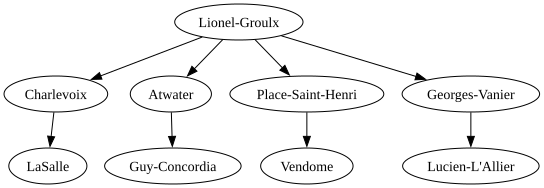

In [7]:
from graphviz import Digraph

# Q3.3
def dessiner_arbre(reseau, depart, niveaux=3):
    distance, precedent = bfs(reseau, depart)
    dot = Digraph(comment=f'Arbre de parcours depuis {depart}')
    dot.node(depart)
    for station, dist in distance.items():
        if dist < niveaux and station != depart:
            dot.node(station)
            dot.edge(precedent[station], station)
    return dot

dot = dessiner_arbre(reseau, "Lionel-Groulx", niveaux=3)
dot

> **Observation — obligatoire.** Le réseau n'est pas un arbre, et pourtant votre dessin en est un. Expliquez pourquoi.
>
> Le dessin montre tous les chemins les plus courts (en arrêts) depuis le départ, limités aux premiers niveaux. Les arêtes viennent de
> `precedent`. Chaque station n'a qu'un seul parent. Cela l'empêche d'être reliée à la racine par deux chemins différents. Or un cycle,
> c'est justement deux chemins entre les mêmes stations.
>>
> Quand le BFS rencontre une station déjà vue, les arêtes qui fermeraient un cycle sont laissées de côté. C'est ainsi que nous coupons les cycles et que notre dessin devient un arbre.
> Remarque : autour de Lionel-Groulx, dans les premiers niveaux, il n'y a de toute façon aucun cycle. Le dessin serait donc un arbre même
> sans le BFS.

## Partie 4 — Dijkstra, en minutes

**Q4.1** — Complétez `plus_petite_case`, `relacher` et `dijkstra`.

In [8]:
INFINI = 9999

def plus_petite_case(distance, barres):
    record = INFINI
    choisie = None
    for station in distance:
        pass  # a completer
    return choisie


def relacher(distance, precedent, a, b, minutes):
    pass  # a completer


def dijkstra(reseau, depart):
    distance = {station: INFINI for station in reseau}
    distance[depart] = 0
    precedent = {}
    barres = set()
    while len(barres) < len(reseau):
        pass  # a completer
    return distance, precedent

> **Observation — obligatoire.** À quoi sert l'ensemble `barres` ? Que se passerait-il si on l'oubliait ?
>
> *(remplacez ce texte par vos phrases)*

**Q4.2** — Complétez `chemin` (la remontée des précédents) et `duree`.

In [9]:
def chemin(precedent, depart, arrivee):
    route = [arrivee]
    # a completer
    return route


def duree(reseau, route):
    total = 0
    # a completer
    return total

> **Observation — obligatoire.** `chemin` remonte à l'envers puis retourne la liste. Pourquoi ne peut-on pas la construire à l'endroit directement ?
>
> *(remplacez ce texte par vos phrases)*

**Q4.3** — Affichez le trajet le plus rapide entre deux stations de votre choix,
avec sa durée.

In [10]:
# Q4.3


> **Observation — obligatoire.** Ce trajet correspond-il à celui que vous prendriez dans la vraie vie ? Si non, qu'est-ce qui manque à notre modèle ?
>
> *(remplacez ce texte par vos phrases)*

## Partie 5 — Comparer les deux, et surligner le chemin

**Q5.1** — Écrivez `comparer(depart, arrivee)` qui affiche, pour chaque algorithme,
le nombre d'arrêts **et** la durée. Testez-la sur **trois** paires de stations, dont
**au moins une** où les deux algorithmes ne donnent pas le même trajet.

In [11]:
# Q5.1


> **Observation — obligatoire.** Sur vos trois paires, à quelle fréquence les deux sont-ils d'accord ? Reliez votre réponse au décompte des durées de la question 2.3.
>
> *(remplacez ce texte par vos phrases)*

**Q5.2** — Sur votre paire divergente, **surlignez le chemin de Dijkstra** dans le
dessin : les arêtes du chemin en **rouge et en épais**, la durée de chaque tronçon en
étiquette, et les stations du chemin remplies d'une couleur.

> **Les attributs à utiliser.** Sur une arête : `color="red"`, `penwidth="3"`,
> `fontcolor="red"`. Sur un sommet : `style="filled"`, `fillcolor="#ffd9d9"`.
> Le reste — quelles arêtes dessiner, comment reconnaître celles du chemin — est à
> vous.

In [12]:
# Q5.2


> **Observation — obligatoire.** Décrivez ce que votre dessin rend visible et que la liste de stations ne montrait pas.
>
> *(remplacez ce texte par vos phrases)*

---
## Partie 6 — Construire un tableau de données

Un modèle a besoin d'un **tableau** : une ligne par exemple, une colonne par
**donnée**, et une colonne à part pour l'**étiquette**.

Ici, **un exemple = une station**, et l'étiquette est sa **ligne**. Les données,
vous les fabriquez avec **votre propre travail des parties 3 et 4**.

On laisse de côté les stations de la ligne jaune : il y en a trop peu.

**Q6.1** — Pour chaque station retenue, fabriquez la liste de ses mesures :

1. son nombre de voisins ;
2. la durée moyenne de ses tronçons ;
3. la durée de son plus long tronçon ;
4. le nombre d'**arrêts** qui la séparent d'un **repère** *(votre BFS)* ;
5. le nombre de **minutes** qui l'en séparent *(votre Dijkstra)*.

Écrivez `mesures(station, nb_reperes)` de façon à pouvoir ajouter des repères
ensuite, et construisez `X_1repere` ainsi que `y`.

In [13]:
REPERES = ["Berri-UQAM", "Snowdon", "Honore-Beaugrand"]

stations_retenues = [s for s in sorted(reseau) if infos_station[s]["ligne"] != "jaune"]
y = [infos_station[s]["ligne"] for s in stations_retenues]
print(len(stations_retenues), "stations retenues")

# Q6.1


66 stations retenues


> **Observation — obligatoire.** Lesquelles de vos cinq mesures viennent des fichiers fournis, et lesquelles viennent de votre propre code ? Qui a choisi les repères ?
>
> *(remplacez ce texte par vos phrases)*

**Q6.2** — Comptez combien de stations portent chaque étiquette, et déduisez-en la
note qu'obtiendrait un modèle qui répondrait **toujours la même chose**.

In [14]:
# Q6.2


> **Observation — obligatoire.** Notez ce pourcentage. C'est la barre que votre modèle devra dépasser pour servir à quelque chose.
>
> *(remplacez ce texte par vos phrases)*

## Partie 7 — Entraîner un modèle, et le noter honnêtement

**Q7.1** — Coupez en deux paquets (70 / 30), entraînez un `DecisionTreeClassifier`,
et affichez **deux** notes : sur les stations apprises, et sur les stations jamais
vues.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Q7.1


> **Observation — obligatoire.** Vos deux notes sont très différentes. Comment s'appelle ce phénomène, et laquelle des deux est honnête ?
>
> *(remplacez ce texte par vos phrases)*

**Q7.2** — Refaites la même chose avec **2** puis **3** repères. Affichez les trois
notes côte à côte.

In [16]:
# Q7.2


> **Observation — obligatoire.** Qu'est-ce qui change, et pourquoi un seul repère ne suffisait-il pas ? Pensez à deux stations situées de part et d'autre du repère.
>
> *(remplacez ce texte par vos phrases)*

**Q7.3** — Sur vos meilleures mesures, comparez un **arbre seul** à une **forêt
aléatoire**. Relancez chacun avec `random_state` valant 0, 1, 2, 3 puis 4, et
affichez pour chaque modèle ses cinq notes, leur **moyenne** et l'**écart** entre la
plus haute et la plus basse.

In [17]:
# Q7.3


> **Observation — obligatoire.** La forêt vous a-t-elle aidés ? Appuyez-vous sur la moyenne ET sur l'écart, puis proposez une explication liée au nombre d'exemples dont vous disposez.
>
> *(remplacez ce texte par vos phrases)*

---
## Partie 8 — Vos conclusions

Répondez en Markdown, **en phrases complètes, en français**. Comptez deux ou trois
phrases par question, et **citez vos propres chiffres**.

**Sur le réseau**

1. Le réseau est-il un **arbre** ? Justifiez avec le nombre de stations et de liens.
2. Quelle station est la mieux connectée, et **pourquoi** celle-là ?
3. Sur vos trois paires, le BFS et Dijkstra donnent-ils souvent la même réponse ?
   Reliez votre réponse au décompte des durées.
4. Décrivez **une** paire où ils diffèrent, et expliquez ce que chacun a optimisé.

**Sur le modèle**

5. Avec un seul repère, quelle note obtenez-vous, et comment se compare-t-elle au
   modèle qui répond toujours la même chose ? Qu'est-ce que ça vous apprend ?
6. Qu'est-ce qui change avec 2 puis 3 repères, et **pourquoi** ?
7. Pourquoi la note sur les stations jamais vues est-elle la seule honnête ?
8. La forêt aléatoire vous a-t-elle aidés ? Appuyez-vous sur les cinq notes et sur
   l'écart.

**Sur l'ensemble**

9. Vos données de la partie 6 viennent de vos propres fonctions. Quel risque cela
   pose-t-il si votre BFS ou votre Dijkstra contient une erreur ?
10. Nommez **une** limite de nos données par rapport au vrai métro, et **une**
    mesure supplémentaire que vous auriez aimé avoir pour le modèle.

### Vos réponses

*(remplacez ce texte)*

1.

2.

3.

4.

5.

6.

7.

8.

9.

10.

---
## Déclaration d'utilisation de l'intelligence artificielle

**Obligatoire, même si vous n'en avez pas utilisé.** Une déclaration absente ou
fausse vaut **0 pour l'ensemble du TP**.

L'IA est permise **pour apprendre**, pas pour produire votre travail. Relisez les
règles de l'énoncé avant de remplir cette section.

**Avez-vous utilisé un outil d'IA ?** _oui / non_

**Si oui, remplissez le tableau :**

| Outil | Pour quelle question | Ce que vous lui avez demandé | Lien de partage de la conversation |
|---|---|---|---|
|  |  |  |  |
|  |  |  |  |

**Confirmez, en écrivant « oui » :**

- Je n'ai **pas** collé l'énoncé du TP, en tout ou en partie, dans une conversation
  avec une IA. → _____
- Je n'ai **pas** collé le contenu des fichiers de données. → _____
- Je comprends chaque ligne de code que je remets et je peux l'expliquer à l'oral.
  → _____

---
**Qui a fait quoi :** *(obligatoire si vous êtes deux)*

---
## Avant de remettre

**Vingt points du TP ne portent pas sur vos réponses** : dix sur la tenue de ce
carnet, dix sur votre usage de Git. Relisez les sections 3 et 4 de l'énoncé avant de
déposer votre travail.

**Le carnet.** Faites **Kernel → Redémarrer et tout exécuter** en dernier, et
vérifiez qu'aucune cellule ne produit d'erreur. Puis relisez-le comme si vous ne
l'aviez pas écrit : est-ce qu'on s'y retrouve ? Est-ce que chaque nombre affiché
s'explique sans aller lire le code ? Reste-t-il des cellules d'essai, des variables
au nom obscur, des observations expédiées ? Le français est-il relu ?

**Le dépôt.** Le nom de votre branche et vos messages de commit suivent la
convention vue en cours. Votre historique doit montrer un travail construit au fil du
temps — et, si vous êtes deux, la contribution des deux.

**L'identification.** Nom, coéquipier et groupe en première cellule, « qui a fait
quoi » à la fin, déclaration d'IA remplie même si la réponse est « non », et le
dossier `donnees/` à côté du carnet.

---

*Ensuite : `Publish branch`, `Create Pull Request`, fusion dans `main`, et le lien du
dépôt sur Omnivox.*